# 3. Comparing retrieval: 60 baseline questions + 10 hard questions

- **Baseline:** the original 60 drug-and-section lookups, unchanged.
- **Challenge:** 10 authored questions with 25 required evidence items, checked against saved FDA text before retrieval.
- **Same experiment settings:** six methods, the same collection and top 10 passages; no app filters, cutoff or LLM answer writing.
- This notebook **reads saved measurements**. Running its cells makes no API calls and does not rerun retrieval.

These are diagnostic checks, not clinical validation. A section match and complete coverage of selected evidence spans measure different things; keep the two groups separate.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.utils.config import digest, load_config, read_json
from src.ingestion.data_loader import load_snapshot
from src.evaluation.section_check import METHODS, make_questions, make_hard_questions

index_path = ROOT / read_json(ROOT / "results/search_latest.json")["run_path"].replace("\\", "/")
index = read_json(index_path)
comparison = read_json(ROOT / "reports/expanded_60/method_comparison.json")
assert comparison["status"] == "complete", "Finish the comparison before reading results."
assert comparison["snapshot_id"] == index["snapshot_id"]
assert comparison["index_run_id"] == index["run_id"]
assert comparison["settings"] == index["selection"], "Search settings changed; rerun the comparison."
source_hash = digest((ROOT / "src/evaluation/section_check.py").read_text(encoding="utf-8"))
assert comparison["source_code_hash"] == source_hash, "Evaluation code changed; rerun the comparison."
names = index["configuration"]["ingestion"]["lookup_names"]
assert load_config()["ingestion"]["lookup_names"] == names
snapshot = load_snapshot(index["snapshot_id"])
expected_questions = make_questions(snapshot, names) + make_hard_questions(snapshot)
assert comparison["questions"] == expected_questions, "Questions or source evidence changed."
assert comparison["comparison_id"] == digest([index, expected_questions, METHODS, source_hash])
questions = pd.DataFrame(comparison["questions"])
assert questions["id"].is_unique and len(questions) == 70
baseline = questions[questions["group"] == "baseline"]
hard = questions[questions["group"] == "hard"]
assert len(baseline) == baseline["drug"].nunique() == 60
assert len(hard) == 10
assert sum(len(q["requirements"]) for q in comparison["questions"] if q["group"] == "hard") == 25

display(Markdown(
    f"**60 drugs | {comparison['corpus_labels']} FDA labels | {comparison['corpus_chunks']:,} passages | "
    f"60 baseline + 10 hard questions**\n\nSaved run: {comparison['completed_at']} (UTC)."
))

**60 drugs | 118 FDA labels | 8,601 passages | 60 baseline + 10 hard questions**

Saved run: 2026-10-25T17:35:19.845081+00:00 (UTC).

## Questions and references

| Group | Questions | What counts as a match? |
|---|---:|---|
| Baseline | 60: 20 uses, 20 dosage, 20 warnings | A passage from an expected drug label and section |
| Hard | 10: 3 vocabulary, 3 constraints, 2 multi-section, 2 near-match | Complete retrieval of a selected exact source span for a required fact |

- Hard references retain source IDs, hashes, exact quotes and character offsets.
- Overlapping passages can jointly cover a span. Gaps, repeated chunks and wrong labels/sections earn no extra credit.
- **Complete evidence:** all required facts have at least one fully covered reference within the first 10 passages.
- **Evidence coverage:** covered requirements / required requirements, averaged equally across questions. This is not exhaustive passage Recall@10.
- Evidence was checked against the repository's saved labels, **without independent clinical review**. Equivalent wording or other valid passages may be missed.

In [2]:
display(baseline["topic"].value_counts().rename("Baseline questions").to_frame())
with pd.option_context("display.max_colwidth", None):
    display(hard[["id", "drug", "topic", "text"]].rename(columns={
        "id": "Question ID", "drug": "Drug", "topic": "Challenge", "text": "Hard question"
    }).reset_index(drop=True))

,Baseline questions
topic,
Uses,20
Dosage,20
Warnings,20


,Question ID,Drug,Challenge,Hard question
0,hard_01,prednisone,Vocabulary,"My body has become used to long-term prednisone. Find the label evidence explaining why suddenly quitting is unsafe, and what someone should tell medical staff and do when a new illness with fever develops."
1,hard_02,gabapentin,Vocabulary,"For gabapentin, find instructions for someone whose kidneys remove medicine very slowly and whose blood is cleaned by a machine. Include both the very-low-kidney-function daily-dose rule and the extra dosing associated with a four-hour filtering session."
2,hard_03,levothyroxine,Vocabulary,"For a morning levothyroxine tablet, find the timing rules around breakfast, calcium or iron supplements, and a hair-and-nail vitamin that can interfere with thyroid blood tests. Retrieve all three instructions rather than just the thyroid condition it treats."
3,hard_04,apixaban,Constraints,"Find apixaban evidence distinguishing the reduced dose for nonvalvular atrial fibrillation when age, weight and creatinine criteria coexist, from the interaction rule for someone already taking 2.5 mg twice daily who also receives a combined P-gp and strong CYP3A4 inhibitor."
4,hard_05,metformin,Constraints,"In immediate-release metformin labeling, distinguish starting treatment with an eGFR of 38 from managing an existing prescription around iodinated contrast. Find the renal initiation limit, circumstances requiring a temporary hold, and kidney-check and restart conditions after imaging."
5,hard_06,sertraline,Constraints,"Locate sertraline label evidence that distinguishes mild from moderate or severe liver impairment and gives the waiting periods for switching to and from an MAOI antidepressant. Include both switching directions, not only a general serotonin syndrome warning."
6,hard_07,warfarin,Multi-section,"Find warfarin evidence explaining why a therapeutic INR does not guarantee freedom from bleeding, together with the monitoring instruction when antibiotics are started or stopped. Retrieve both the residual-risk statement and the drug-change action, rather than a generic bleeding side-effect list."
7,hard_08,atorvastatin,Multi-section,"Find atorvastatin evidence linking clarithromycin to a dose ceiling and describing the muscle-safety action when CK is markedly raised or myopathy is suspected. Retrieve the interaction restriction and the warning action, not cholesterol-lowering indications or a general list of muscle symptoms."
8,hard_09,clopidogrel,Near-match,"For clopidogrel and acid-suppressing medicines, locate evidence addressing whether taking omeprazole twelve hours apart removes the interaction, and whether pantoprazole has the same effect. Retrieve the avoidance instruction, the separated-dose finding and the comparison with other proton-pump inhibitors."
9,hard_10,ibuprofen,Near-match,"For the acetaminophen plus ibuprofen dual-action caplets, locate directions for people aged twelve and over, the maximum in one day, and the acetaminophen-related warning about taking another product with the same ingredient. Exclude instructions for plain ibuprofen tablets."


## Methods and fair comparison

| Method | What it does |
|---|---|
| Keyword | Matches words |
| BM25 | Weights matching words by distinctiveness |
| Semantic | Searches embedding similarity |
| Hybrid: rank fusion | Combines lexical and semantic result positions |
| Hybrid: score fusion | Combines adjusted lexical and semantic scores |
| Hybrid + reranking | A local cross-encoder scores each hybrid candidate against the question |

- All six methods use unchanged saved settings and the same passages; no tuning on these questions.
- Timing includes ranking/reranking after warm-up; excludes model loading, question embedding, indexing and answer writing.
- The challenge is an authored stress test, not an independently validated difficulty scale or untouched held-out set.

In [3]:
method_names = {
    "keyword": "Keyword", "bm25": "BM25", "dense": "Semantic",
    "hybrid_rrf": "Hybrid: rank fusion", "hybrid_normalized": "Hybrid: score fusion",
    "hybrid_rerank": "Hybrid + reranking",
}
methods = {m["method"]: m for m in comparison["methods"]}
assert set(methods) == set(method_names)
assert all(m["questions"] == 70 for m in methods.values())
baseline_results = pd.DataFrame({m: methods[m]["groups"]["baseline"] for m in method_names}).T
hard_results = pd.DataFrame({m: methods[m]["groups"]["hard"] for m in method_names}).T
assert baseline_results["questions"].eq(60).all() and hard_results["questions"].eq(10).all()

def counts(frame, field):
    return [f"{int(row[field])}/{int(row['questions'])} ({row[field] / row['questions']:.0%})"
            for _, row in frame.iterrows()]

## Baseline: original 60 section lookups

**Found first** and **found in top 10** refer to the expected label/section, not a complete medical answer. The question text and reference sections match the original 60-question comparison.

In [4]:
baseline_table = pd.DataFrame(index=baseline_results.index)
baseline_table["Found first"] = counts(baseline_results, "found_first")
baseline_table["Found in top 10"] = counts(baseline_results, "found_in_10")
baseline_table["Mean ranking time (ms)"] = baseline_results["average_ms"].round(1)
display(baseline_table.rename(index=method_names))

,Found first,Found in top 10,Mean ranking time (ms)
Keyword,3/60 (5%),7/60 (12%),54.7
BM25,16/60 (27%),41/60 (68%),88.6
Semantic,36/60 (60%),58/60 (97%),5.1
Hybrid: rank fusion,29/60 (48%),56/60 (93%),100.3
Hybrid: score fusion,37/60 (62%),58/60 (97%),98.1
Hybrid + reranking,42/60 (70%),60/60 (100%),4533.1


## Challenge: 10 questions requiring specific evidence

- **Any required evidence:** at least one required span is fully retrieved in the top 10.
- **Complete evidence:** all required evidence items are covered in the top 10.
- **Mean coverage:** average fraction of requirements covered per question.
- With only 10 questions, one additional complete success changes the success rate by **10 percentage points**.

In [5]:
hard_table = pd.DataFrame(index=hard_results.index)
hard_table["Any required evidence in top 10"] = counts(hard_results, "found_in_10")
hard_table["Complete evidence in top 10"] = counts(hard_results, "complete_in_10")
hard_table["Mean evidence coverage"] = hard_results["evidence_coverage"].map(lambda value: f"{value:.1%}")
hard_table["Mean ranking time (ms)"] = hard_results["average_ms"].round(1)
display(hard_table.rename(index=method_names))

,Any required evidence in top 10,Complete evidence in top 10,Mean evidence coverage,Mean ranking time (ms)
Keyword,7/10 (70%),1/10 (10%),40.0%,73.4
BM25,9/10 (90%),4/10 (40%),68.3%,241.9
Semantic,9/10 (90%),5/10 (50%),71.7%,5.0
Hybrid: rank fusion,10/10 (100%),6/10 (60%),83.3%,233.7
Hybrid: score fusion,10/10 (100%),6/10 (60%),83.3%,257.1
Hybrid + reranking,9/10 (90%),4/10 (40%),68.3%,5623.4


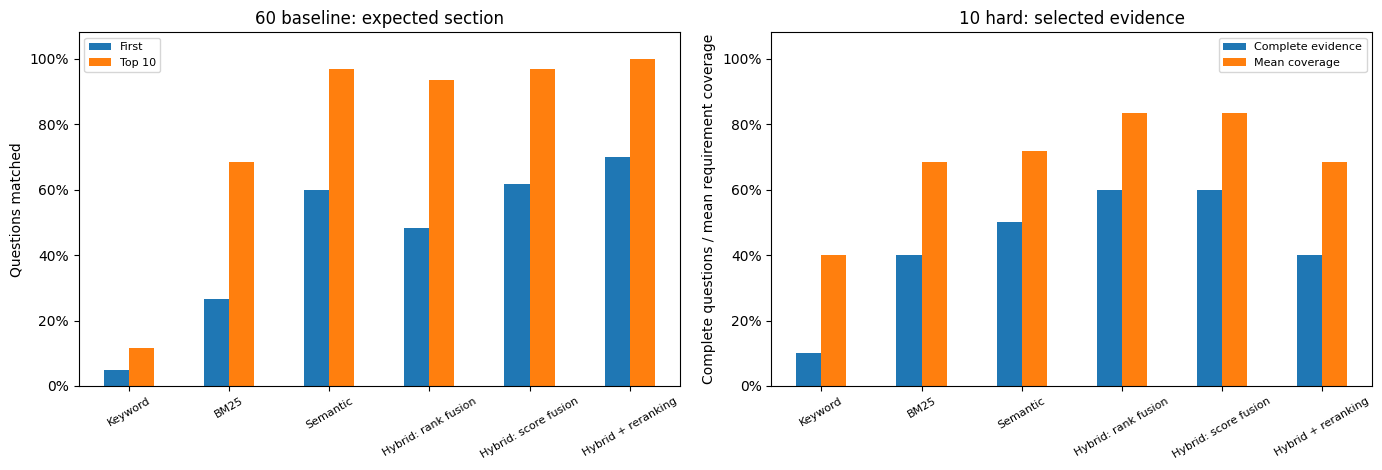

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
base_scores = baseline_results[["found_first", "found_in_10"]].div(baseline_results["questions"], axis=0)
base_scores.rename(index=method_names, columns={"found_first": "First", "found_in_10": "Top 10"}).plot.bar(ax=axes[0], rot=30)
challenge_scores = pd.DataFrame({
    "Complete evidence": hard_results["complete_in_10"] / hard_results["questions"],
    "Mean coverage": hard_results["evidence_coverage"],
}).rename(index=method_names)
challenge_scores.plot.bar(ax=axes[1], rot=30)
for ax, title, ylabel in zip(axes, ["60 baseline: expected section", "10 hard: selected evidence"],
                             ["Questions matched", "Complete questions / mean requirement coverage"]):
    ax.set(title=title, xlabel="", ylabel=ylabel, ylim=(0, 1.08))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis="x", labelsize=8)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Where did methods miss evidence?

Each cell below is **required items retrieved / required items**. For example, `2/3` means the method found useful evidence but missed at least one selected requirement. This table uses question IDs because a drug can have several questions.

In [7]:
hard_rows = []
for method in comparison["methods"]:
    for row in method["per_question"]:
        if row["group"] == "hard":
            hard_rows.append({
                "Question ID": row["id"], "Drug": row["drug"], "Challenge": row["topic"],
                "Method": method_names[method["method"]],
                "Evidence found": f"{row['requirements_found']}/{row['requirements_total']}",
            })
failures = pd.DataFrame(hard_rows).pivot(index=["Question ID", "Drug", "Challenge"], columns="Method", values="Evidence found")
display(failures.reindex(columns=list(method_names.values())))

,,Method,Keyword,BM25,Semantic,Hybrid: rank fusion,Hybrid: score fusion,Hybrid + reranking
Question ID,Drug,Challenge,,,,,,
hard_01,prednisone,Vocabulary,0/2,2/2,2/2,2/2,2/2,2/2
hard_02,gabapentin,Vocabulary,0/2,0/2,2/2,2/2,2/2,0/2
hard_03,levothyroxine,Vocabulary,2/3,2/3,2/3,2/3,2/3,2/3
hard_04,apixaban,Constraints,0/2,1/2,1/2,2/2,2/2,1/2
hard_05,metformin,Constraints,1/3,3/3,3/3,3/3,3/3,3/3
hard_06,sertraline,Constraints,2/3,2/3,0/3,2/3,2/3,2/3
hard_07,warfarin,Multi-section,1/2,1/2,1/2,1/2,1/2,1/2
hard_08,atorvastatin,Multi-section,1/2,1/2,1/2,1/2,1/2,1/2
hard_09,clopidogrel,Near-match,3/3,3/3,3/3,3/3,3/3,3/3


## Inspect one hard question

Change `question_id` and `method` below. Inspect the reference facts, missing items and the first three returned passages. These excerpts help explain rankings; an uncredited passage may still contain equivalent evidence and needs human review.

In [8]:
question_id = "hard_05"
method = "hybrid_rerank"
question = next(q for q in comparison["questions"] if q["id"] == question_id and q["group"] == "hard")
row = next(r for r in methods[method]["per_question"] if r["id"] == question_id)
display(Markdown(f"**{question_id}:** {question['text']}"))
reference_rows = []
for required in question["requirements"]:
    reference = next(r for r in question["references"] if r["requirement_id"] == required["id"])
    reference_rows.append({
        "Required evidence": required["description"],
        "Retrieved": required["id"] in row["matched_requirements"],
        "Section": reference["section"], "Exact reference text": reference["quote"],
        "Label set": reference["set_id"], "Start": reference["start"], "End": reference["end"],
    })
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(reference_rows))
chunk_by_id = {c["chunk_id"]: c for c in read_json(index_path.parent / "chunks.json")}
examples = [{"Rank": r["rank"], "Raw score": round(r["score"], 3), "Section": r["section"],
             "Label set": r["set_id"], "Passage preview": chunk_by_id[r["chunk_id"]]["text"][:350]}
            for r in row["results"][:3]]
display(Markdown(f"**{method_names[method]}:** {row['requirements_found']}/{row['requirements_total']} evidence items; "
                 f"first complete reference at rank {row['first_matching_rank'] or 'not found'}. Scores are not probabilities."))
with pd.option_context("display.max_colwidth", 180):
    display(pd.DataFrame(examples))

**hard_05:** In immediate-release metformin labeling, distinguish starting treatment with an eGFR of 38 from managing an existing prescription around iodinated contrast. Find the renal initiation limit, circumstances requiring a temporary hold, and kidney-check and restart conditions after imaging.

,Required evidence,Retrieved,Section,Exact reference text,Label set,Start,End
0,Do not initiate at eGFR 30 to 45,True,dosage_and_administration,Initiation of metformin hydrochloride tablets in patients with an eGFR between 30 – 45 mL/minute/1.73 m 2 is not recommended.,4d3dbf6f-1c8a-4daa-8343-8cd8f64a65cd,2386,2511
1,Contrast-related hold and qualifying conditions,True,dosage_and_administration,"Discontinue metformin hydrochloride tablets at the time of, or prior to, an iodinated contrast imaging procedure in patients with an eGFR between 30 and 60 mL/min/1.73 m 2 ; in patients with a history of liver disease, alcoholism, or heart failure; or in patients who will be administered intra-arterial iodinated contrast.",4d3dbf6f-1c8a-4daa-8343-8cd8f64a65cd,2868,3191
2,Recheck after 48 hours and restart only if stable,True,dosage_and_administration,Re-evaluate eGFR 48 hours after the imaging procedure; restart metformin hydrochloride tablets if renal function is stable.,4d3dbf6f-1c8a-4daa-8343-8cd8f64a65cd,3192,3315


**Hybrid + reranking:** 3/3 evidence items; first complete reference at rank 7. Scores are not probabilities.

,Rank,Raw score,Section,Label set,Passage preview
0,1,-0.480,dosage_and_administration,05999192-ebc6-4198-bd1e-f46abbfb4f8a,icated in patients with an estimated glomerular filtration rate (eGFR) below 30 mL/minute/1.73 m 2 . • Initiation of metformin hydrochloride extended-release tablets in patient...
1,2,-0.586,warnings_and_cautions,05999192-ebc6-4198-bd1e-f46abbfb4f8a,"to, an iodinated contrast imaging procedure in patients with an eGFR between 30 and 60 mL/min/1.73 m 2 ; in patients with a history of hepatic impairment, alcoholism or heart ..."
2,3,-0.664,warnings_and_cautions,05999192-ebc6-4198-bd1e-f46abbfb4f8a,"o In patients taking metformin hydrochloride extended-release tablets whose eGFR falls below 45 mL/min/1.73 m 2 , assess the benefit and risk of continuing therapy. • Drug int..."


## Findings and limits

The following summary is calculated from the saved run. It describes only these source-based checks; a good ranking does not establish a safe, complete or correct clinical answer.

In [9]:
best = int(hard_results["complete_in_10"].max())
leaders = [method_names[m] for m in hard_results.index if hard_results.loc[m, "complete_in_10"] == best]
best_coverage = hard_results["evidence_coverage"].max()
coverage_leaders = [method_names[m] for m in hard_results.index
                    if abs(hard_results.loc[m, "evidence_coverage"] - best_coverage) < 1e-9]
rerank = methods["hybrid_rerank"]["groups"]["hard"]
never_complete = [q["id"] for q in comparison["questions"] if q["group"] == "hard" and
                  not any(next(r for r in m["per_question"] if r["id"] == q["id"])["all_evidence_found"]
                          for m in comparison["methods"])]
fastest = hard_results["average_ms"].idxmin()
display(Markdown(
    f"- Highest complete-evidence count: **{best}/10**, achieved by **{', '.join(leaders)}**.\n"
    f"- Highest mean evidence coverage: **{best_coverage:.1%}** ({', '.join(coverage_leaders)}).\n"
    f"- Hybrid + reranking found at least one requirement for **{rerank['found_in_10']}/10**, "
    f"but every selected requirement for **{rerank['complete_in_10']}/10**. A hit alone can hide missing evidence.\n"
    f"- Fastest mean challenge ranking: **{method_names[fastest]}**, "
    f"**{hard_results.loc[fastest, 'average_ms']:.1f} ms**; provider embedding and model startup are excluded.\n"
    f"- Questions with no complete result from any method: **{', '.join(never_complete) or 'none'}**. "
    "Inspect their reference and passage tables before attributing a cause.\n"
    "- References are selected exact spans, not exhaustive relevance judgments or independent clinical review.\n"
    "- Keep baseline and challenge scores separate. Ten authored questions and unchanged settings do not establish broad reliability."
))

- Highest complete-evidence count: **6/10**, achieved by **Hybrid: rank fusion, Hybrid: score fusion**.
- Highest mean evidence coverage: **83.3%** (Hybrid: rank fusion, Hybrid: score fusion).
- Hybrid + reranking found at least one requirement for **9/10**, but every selected requirement for **4/10**. A hit alone can hide missing evidence.
- Fastest mean challenge ranking: **Semantic**, **5.0 ms**; provider embedding and model startup are excluded.
- Questions with no complete result from any method: **hard_03, hard_06, hard_07, hard_08**. Inspect their reference and passage tables before attributing a cause.
- References are selected exact spans, not exhaustive relevance judgments or independent clinical review.
- Keep baseline and challenge scores separate. Ten authored questions and unchanged settings do not establish broad reliability.

## Reproduce the comparison

- Questions, exact references, scores and both groups' results: `reports/expanded_60/method_comparison.json`.
- The original FDA collection and index are reused; no document re-embedding or index rebuild is needed.
- New question embeddings can incur API usage. App filters, the cutoff and LLM answers remain outside this experiment.
- Reuse checks index/settings, questions and evaluator hash; it does not hash every retrieval dependency.

Run or resume measurements:

```powershell
uv run --locked --no-sync python scripts/compare_search_methods.py
```

Refresh this notebook's saved displays only (research dependencies required):

```powershell
uv run --locked --no-sync python scripts/execute_notebooks.py --notebook 03_retrieval_pipeline_benchmark
```